In [7]:
import os, glob, time
import pandas as pd
import torch
from torch import nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torchvision import datasets

from config import BATCH, P, EARLY_GRID, SEEDS
from models import mlp

In [8]:
tr = datasets.FashionMNIST("./data", train=True, download=True)
te = datasets.FashionMNIST("./data", train=False, download=True)
Xtr = tr.data.float().view(-1, 784) / 255
Xte = te.data.float().view(-1, 784) / 255
ytr, yte = tr.targets, te.targets

# validation : 10 000 exemples tirés du train (split fixe)
perm = torch.randperm(len(Xtr), generator=torch.Generator().manual_seed(0))
Xva, yva = Xtr[perm[:10000]], ytr[perm[:10000]]
Xtr, ytr = Xtr[perm[10000:]], ytr[perm[10000:]]

# normalisation avec les stats du train uniquement
mu, sd = Xtr.mean(), Xtr.std()
Xtr, Xva, Xte = (Xtr - mu) / sd, (Xva - mu) / sd, (Xte - mu) / sd
print(Xtr.shape, Xva.shape, Xte.shape)

torch.Size([50000, 784]) torch.Size([10000, 784]) torch.Size([10000, 784])


## Paramètres propres à ce cadre

`EARLY_GRID` (dans `config.py`) donne la durée de la phase de dropout en fraction de `EPOCHS` :
0 = pas de dropout, 1 = dropout standard (tout l'entraînement), entre les deux = early dropout.

In [9]:
CADRE = "mlp_fmnist"
#WIDTH = 16           # taille des couches caches
#EPOCHS = 50          #  a calibrer

OUT = "resultats"

# Calibration du nombre d'epochs et de la largeur du modele
Le papier dit que l'early dropout aide les modeles en sous-apprentissage. Hors en fonction de la taille de l'architecture et du data set les modeles ont tendances a overfit.  
**Le problème** : comment savoir si un modèle est en sous-apprentissage ? On utilise le critère du papier, qui sert de thermomètre : on entraîne le même modèle sans dropout puis avec dropout standard, et on regarde la différence d’accuracy de validation (le delta).  
Le dropout standard retire de la capacité au modèle.  

- Si le modèle surapprend, retirer de la capacité l’aide : delta > 0.  
- Si le modèle sous-apprend, il manque déjà de capacité, et en retirer encore le pénalise : delta < 0.

In [10]:
CALIB_WIDTHS = [16, 32, 64]
CALIB_EPOCHS = [10, 20]
CALIB_GRID = [0, 1]          # 0 = sans dropout, 1 = dropout standard
CALIB_SEEDS = [0, 1]

for WIDTH in CALIB_WIDTHS:
    for EPOCHS in CALIB_EPOCHS:
        for frac in CALIB_GRID:
            T_EARLY = round(frac * EPOCHS)
            mode = "none" if frac == 0 else "standard"
            for seed in CALIB_SEEDS:
                fichier = f"{OUT}/{CADRE}_w{WIDTH}_e{EPOCHS}_frac{frac}_s{seed}.csv"
                if os.path.exists(fichier):
                    continue
                torch.manual_seed(seed)
                model, opt = mlp(784, 10, couche_cache=WIDTH)
                sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
                rows = []
                for epoch in range(EPOCHS):
                    rate = P if epoch < T_EARLY else 0.0
                    for m in model.modules():
                        if isinstance(m, nn.Dropout):
                            m.p = rate
                    model.train()
                    perm = torch.randperm(len(Xtr))
                    for i in range(0, len(Xtr), BATCH):
                        idx = perm[i:i + BATCH]
                        loss = F.cross_entropy(model(Xtr[idx]), ytr[idx])
                        opt.zero_grad(); loss.backward(); opt.step()
                    sched.step()
                    model.eval()
                    with torch.no_grad():
                        out_tr, out_va, out_te = model(Xtr), model(Xva), model(Xte)
                        rows.append({
                            "cadre": CADRE, "width": WIDTH, "epochs": EPOCHS, "batch": BATCH, "p": P,
                            "frac": frac, "t_early": T_EARLY, "mode": mode, "seed": seed,
                            "epoch": epoch, "rate": rate,
                            "train_loss": F.cross_entropy(out_tr, ytr).item(),
                            "val_loss": F.cross_entropy(out_va, yva).item(),
                            "val_acc": (out_va.argmax(1) == yva).float().mean().item(),
                            "test_acc": (out_te.argmax(1) == yte).float().mean().item(),
                        })
                pd.DataFrame(rows).to_csv(fichier, index=False)
                print(f"w{WIDTH} e{EPOCHS} {mode:8s} seed {seed}  val acc {rows[-1]['val_acc']:.4f}")

In [11]:
cal = pd.concat(pd.read_csv(f) for f in glob.glob(f"{OUT}/{CADRE}_w*_e*_frac*_s*.csv"))
cal = cal[cal.width.isin(CALIB_WIDTHS) & cal.epochs.isin(CALIB_EPOCHS) & cal.frac.isin(CALIB_GRID)]

# valeur finale = moyenne des 5 dernières epochs de chaque run
fin = (cal[cal.epoch >= cal.epochs - 5]
       .groupby(["width", "epochs", "frac", "seed"])[["train_loss", "val_loss", "val_acc"]].mean()
       .reset_index())

t = fin.pivot_table(index=["width", "epochs", "seed"], columns="frac", values="val_acc")
t["delta"] = (t[1] - t[0]) * 100                         # standard - aucun, en points
tab = t.groupby(["width", "epochs"]).agg(
    acc_sans_dropout=(0, "mean"),
    delta_moy=("delta", "mean"),
    delta_min=("delta", "min"),
    delta_max=("delta", "max"),
)
tab["sous_apprentissage"] = tab.delta_max <= -0.5         # les 2 graines perdent au moins 0.5 pt
tab.round(3)

acc_sans_dropout  delta_moy  delta_min  delta_max  \
width epochs                                                      
16    10                 0.857     -1.024     -1.098     -0.950   
      20                 0.865     -1.110     -1.334     -0.952   
32    10                 0.870     -0.358     -0.448     -0.268   
      20                 0.879     -0.365     -0.422     -0.308   
64    10                 0.880     -0.129     -0.188     -0.070   
      20                 0.888     -0.054     -0.158      0.050   

              sous_apprentissage  
width epochs                      
16    10                    True  
      20                    True  
32    10                   False  
      20                   False  
64    10                   False  
      20                   False

On remarque que la largeur du modele est la source principal de sous apprentissage. On test donc sur plus d'epochs

### On relance donc une nouvelle calibration sur les epochs

In [12]:
GE_WIDTH = 16
GE_EPOCHS = [20, 50, 100]      # 20 est déjà fait (sauté), sert de référence dans le tableau
GE_GRID = [0, 1]               # 0 = sans dropout, 1 = dropout standard
GE_SEEDS = [0, 1]

for ep_total in GE_EPOCHS:
    for frac in GE_GRID:
        t_early = round(frac * ep_total)
        mode = "none" if frac == 0 else "standard"
        for seed in GE_SEEDS:
            fichier = f"{OUT}/{CADRE}_w{GE_WIDTH}_e{ep_total}_frac{frac}_s{seed}.csv"
            if os.path.exists(fichier):
                print("déjà fait :", fichier)
                continue

            torch.manual_seed(seed)
            model, opt = mlp(784, 10, couche_cache=GE_WIDTH)
            sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=ep_total)
            rows = []
            t0 = time.time()

            for epoch in range(ep_total):
                rate = P if epoch < t_early else 0.0
                for m in model.modules():
                    if isinstance(m, nn.Dropout):
                        m.p = rate

                model.train()
                perm = torch.randperm(len(Xtr))
                for i in range(0, len(Xtr), BATCH):
                    idx = perm[i:i + BATCH]
                    loss = F.cross_entropy(model(Xtr[idx]), ytr[idx])
                    opt.zero_grad()
                    loss.backward()
                    opt.step()
                sched.step()

                model.eval()
                with torch.no_grad():
                    out_tr, out_va, out_te = model(Xtr), model(Xva), model(Xte)
                    rows.append({
                        "cadre": CADRE, "width": GE_WIDTH, "epochs": ep_total, "batch": BATCH, "p": P,
                        "frac": frac, "t_early": t_early, "mode": mode, "seed": seed,
                        "epoch": epoch, "rate": rate,
                        "train_loss": F.cross_entropy(out_tr, ytr).item(),
                        "val_loss": F.cross_entropy(out_va, yva).item(),
                        "val_acc": (out_va.argmax(1) == yva).float().mean().item(),
                        "test_acc": (out_te.argmax(1) == yte).float().mean().item(),
                    })

            pd.DataFrame(rows).to_csv(fichier, index=False)
            print(f"w{GE_WIDTH} e{ep_total} {mode:8s} seed {seed}  val acc {rows[-1]['val_acc']:.4f}  ({time.time() - t0:.0f}s)")

ge = pd.concat(pd.read_csv(f) for f in glob.glob(f"{OUT}/{CADRE}_w{GE_WIDTH}_e*_frac*_s*.csv"))
ge = ge[ge.epochs.isin(GE_EPOCHS) & ge.frac.isin(GE_GRID) & ge.seed.isin(GE_SEEDS)]

# valeur finale d'un run = moyenne des 5 dernières epochs
ge_fin = (ge[ge.epoch >= ge.epochs - 5]
          .groupby(["epochs", "frac", "seed"])[["train_loss", "val_loss", "val_acc"]].mean()
          .reset_index())

# delta = standard - sans dropout, par graine, en points
t = ge_fin.pivot_table(index=["epochs", "seed"], columns="frac", values="val_acc")
t["delta"] = (t[1] - t[0]) * 100

# remontée de la loss de validation sans dropout : fin de run - minimum atteint
nd = ge[ge.frac == 0]
remontee = (nd.groupby(["epochs", "seed"]).apply(
    lambda d: d[d.epoch >= d.epochs.iloc[0] - 5].val_loss.mean() - d.val_loss.min()))

ge_tab = t.groupby("epochs").agg(
    acc_sans_dropout=(0, "mean"),
    delta_moy=("delta", "mean"),
    delta_min=("delta", "min"),
    delta_max=("delta", "max"),
)
ge_tab["remontee_val_loss"] = remontee.groupby("epochs").mean()
ge_tab["sous_apprentissage"] = ge_tab.delta_max <= -0.5
ge_tab["pas_de_surapprentissage"] = ge_tab.remontee_val_loss < 0.01
ge_tab.round(4)

déjà fait : resultats/mlp_fmnist_w16_e20_frac0_s0.csv
déjà fait : resultats/mlp_fmnist_w16_e20_frac0_s1.csv
déjà fait : resultats/mlp_fmnist_w16_e20_frac1_s0.csv
déjà fait : resultats/mlp_fmnist_w16_e20_frac1_s1.csv
déjà fait : resultats/mlp_fmnist_w16_e50_frac0_s0.csv
déjà fait : resultats/mlp_fmnist_w16_e50_frac0_s1.csv
déjà fait : resultats/mlp_fmnist_w16_e50_frac1_s0.csv
déjà fait : resultats/mlp_fmnist_w16_e50_frac1_s1.csv
déjà fait : resultats/mlp_fmnist_w16_e100_frac0_s0.csv
déjà fait : resultats/mlp_fmnist_w16_e100_frac0_s1.csv
déjà fait : resultats/mlp_fmnist_w16_e100_frac1_s0.csv
déjà fait : resultats/mlp_fmnist_w16_e100_frac1_s1.csv


C:\Users\User\AppData\Local\Temp\ipykernel_23620\1930512316.py:68: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  remontee = (nd.groupby(["epochs", "seed"]).apply(


,acc_sans_dropout,delta_moy,delta_min,delta_max,remontee_val_loss,sous_apprentissage,pas_de_surapprentissage
epochs,,,,,,,
20,0.8652,-1.080,-1.166,-0.994,0.0008,True,True
50,0.8670,-0.699,-0.836,-0.562,0.0033,True,True
100,0.8669,-0.715,-0.958,-0.472,0.0356,False,False


### On retient une largeur de 16 et on test : 20 et 50 epochs
La calibration valide les deux budgets (sous-apprentissage, et la val loss ne remonte pas). À 20 epochs le modèle n'a pas fini de converger, à 50 il atteint son plafond de capacité.
On lance la grille sur les deux pour voir si l'effet de l'early dropout dépend du budget : est-ce qu'il fait atteindre un meilleur point final (ce que dit le papier) ou est-ce qu'il aide seulement en début d'entraînement ?

In [13]:
CADRE = "mlp_fmnist"
WIDTH = 16
EPOCHS_LIST = [20, 50]
SEEDS = [0, 1, 2, 3, 4]

for E in EPOCHS_LIST:
    print(E, "epochs :", [round(frac * E) for frac in EARLY_GRID], "epochs de dropout")

20 epochs : [0, 2, 4, 6, 10, 20] epochs de dropout
50 epochs : [0, 5, 10, 15, 25, 50] epochs de dropout


## Entraînement (un CSV par run, les runs déjà faits sont sautés)

In [14]:
for EPOCHS in EPOCHS_LIST:
    for frac in EARLY_GRID:
        T_EARLY = round(frac * EPOCHS)
        mode = "none" if frac == 0 else ("standard" if frac == 1 else "early")

        for seed in SEEDS:
            fichier = f"{OUT}/{CADRE}_w{WIDTH}_e{EPOCHS}_frac{frac}_s{seed}.csv"
            if os.path.exists(fichier):
                continue

            torch.manual_seed(seed)
            model, opt = mlp(784, 10, couche_cache=WIDTH)
            sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
            rows = []
            t0 = time.time()

            for epoch in range(EPOCHS):
                rate = P if epoch < T_EARLY else 0.0
                for m in model.modules():
                    if isinstance(m, nn.Dropout):
                        m.p = rate

                model.train()
                perm = torch.randperm(len(Xtr))
                for i in range(0, len(Xtr), BATCH):
                    idx = perm[i:i + BATCH]
                    loss = F.cross_entropy(model(Xtr[idx]), ytr[idx])
                    opt.zero_grad()
                    loss.backward()
                    opt.step()
                sched.step()

                model.eval()
                with torch.no_grad():
                    out_tr, out_va, out_te = model(Xtr), model(Xva), model(Xte)
                    rows.append({
                        "cadre": CADRE, "width": WIDTH, "epochs": EPOCHS, "batch": BATCH, "p": P,
                        "frac": frac, "t_early": T_EARLY, "mode": mode, "seed": seed,
                        "epoch": epoch, "rate": rate,
                        "train_loss": F.cross_entropy(out_tr, ytr).item(),
                        "val_loss": F.cross_entropy(out_va, yva).item(),
                        "val_acc": (out_va.argmax(1) == yva).float().mean().item(),
                        "test_acc": (out_te.argmax(1) == yte).float().mean().item(),
                    })

            pd.DataFrame(rows).to_csv(fichier, index=False)
            print(f"e{EPOCHS} frac {frac:<4} seed {seed}  val acc {rows[-1]['val_acc']:.4f}  ({time.time() - t0:.0f}s)")

## Analyse : relit tous les CSV de ce cadre

In [15]:
# comparaison des 2 budgets : gain par rapport à "sans dropout", graine par graine
comp = []
for E in EPOCHS_LIST:
    d = pd.concat(pd.read_csv(f) for f in glob.glob(f"{OUT}/{CADRE}_w{WIDTH}_e{E}_frac*_s*.csv"))
    d = d[d.seed.isin(SEEDS) & d.frac.isin(EARLY_GRID)]
    f = (d[d.epoch >= E - 5]
         .groupby(["frac", "seed"])[["train_loss", "val_acc", "test_acc"]].mean()
         .reset_index())
    b = f[f.frac == 0].set_index("seed")
    for col in ["train_loss", "val_acc", "test_acc"]:
        f[f"d_{col}"] = f[col].values - b.loc[f.seed, col].values
    f["epochs"] = E
    comp.append(f)
comp = pd.concat(comp)

T95 = {2: 12.71, 3: 4.30, 4: 3.18, 5: 2.78}          # quantiles de Student à 95 %
ic = lambda x: T95[len(x)] * x.std() / len(x) ** 0.5

tab = comp.groupby(["epochs", "frac"]).agg(
    gain_val=("d_val_acc", lambda x: 100 * x.mean()),
    ic_val=("d_val_acc", lambda x: 100 * ic(x)),
    gain_test=("d_test_acc", lambda x: 100 * x.mean()),
    ic_test=("d_test_acc", lambda x: 100 * ic(x)),
    d_train_loss=("d_train_loss", "mean"),
    ic_train_loss=("d_train_loss", ic),
)
tab["test_significatif"] = (tab.gain_test.abs() > tab.ic_test)
tab["train_loss_significatif"] = (tab.d_train_loss.abs() > tab.ic_train_loss)
tab.round(3)

gain_val  ic_val  gain_test  ic_test  d_train_loss  \
epochs frac                                                       
20     0.0      0.000   0.000      0.000    0.000         0.000   
       0.1      0.106   0.276      0.074    0.265        -0.015   
       0.2     -0.020   0.292      0.054    0.316        -0.011   
       0.3     -0.233   0.291     -0.016    0.361        -0.006   
       0.5     -0.493   0.179     -0.285    0.262         0.005   
       1.0     -1.110   0.188     -0.890    0.226         0.026   
50     0.0      0.000   0.000      0.000    0.000         0.000   
       0.1     -0.238   0.663     -0.159    0.469        -0.011   
       0.2     -0.354   0.655     -0.256    0.369        -0.007   
       0.3     -0.446   0.472     -0.304    0.310         0.000   
       0.5     -0.746   0.508     -0.545    0.381         0.014   
       1.0     -1.223   0.620     -0.836    0.341         0.039   

             ic_train_loss  test_significatif  train_loss_significatif  
epochs frac                                                             
20     0.0           0.000              False                    False  
       0.1           0.007              False                     True  
       0.2           0.007              False                     True  
       0.3           0.007              False                    False  
       0.5           0.007               True                    False  
       1.0           0.006               True                     True  
50     0.0           0.000              False                    False  
       0.1           0.008              False                     True  
       0.2           0.005              False                     True  
       0.3           0.004              False                    False  
       0.5           0.006               True                     True  
       1.0           0.007               True                     True

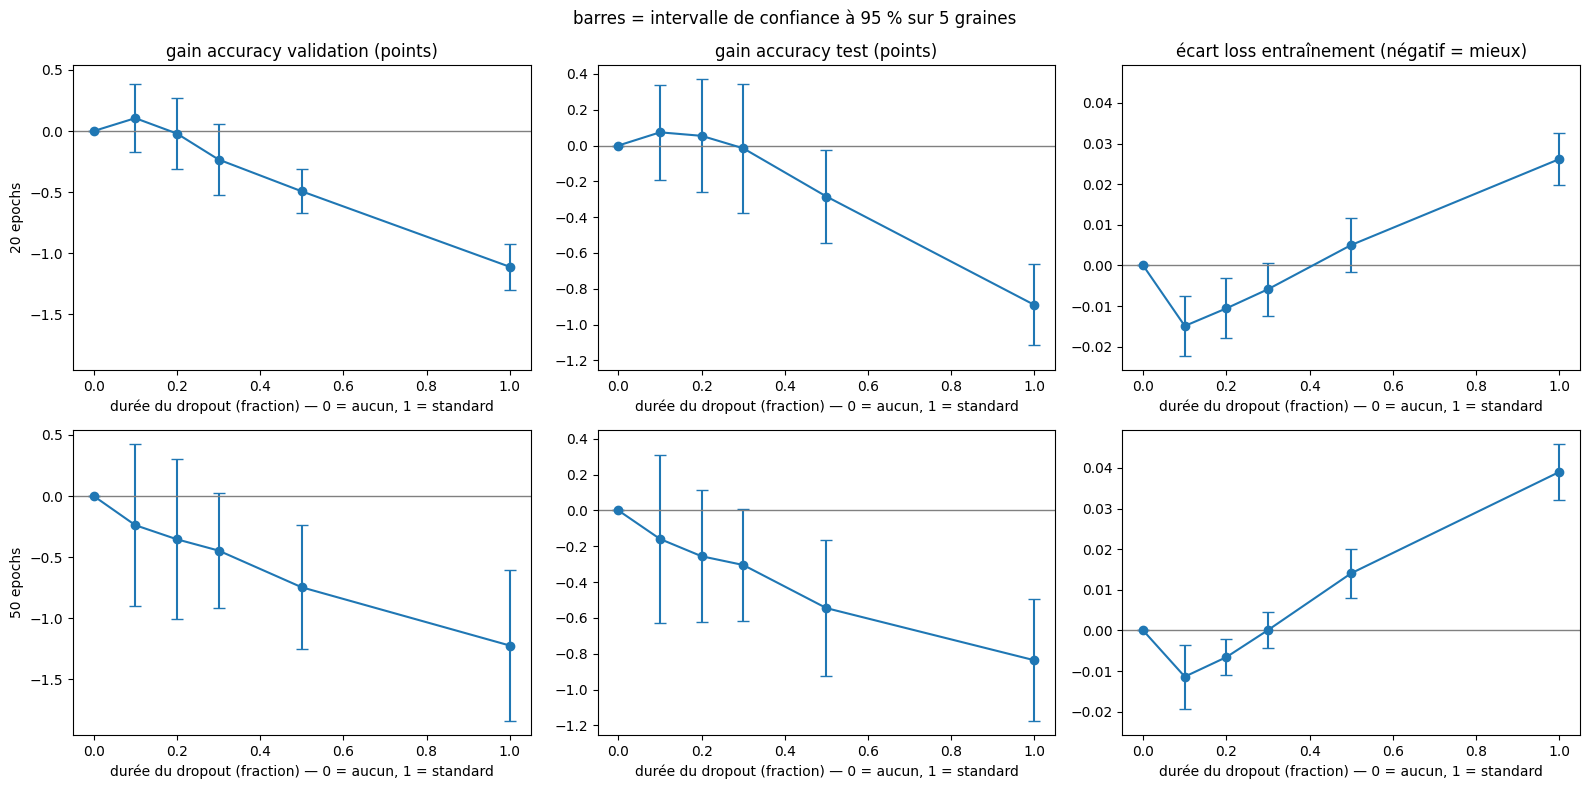

In [16]:
# gains par rapport à "sans dropout" : une ligne par budget, IC à 95 % sur les graines
fig, axes = plt.subplots(len(EPOCHS_LIST), 3, figsize=(16, 4 * len(EPOCHS_LIST)), sharey="col")
for r, E in enumerate(EPOCHS_LIST):
    t = tab.loc[E]
    axes[r, 0].errorbar(t.index, t.gain_val, yerr=t.ic_val, marker="o", capsize=4)
    axes[r, 1].errorbar(t.index, t.gain_test, yerr=t.ic_test, marker="o", capsize=4)
    axes[r, 2].errorbar(t.index, t.d_train_loss, yerr=t.ic_train_loss, marker="o", capsize=4)
    axes[r, 0].set_ylabel(f"{E} epochs")
    for ax in axes[r]:
        ax.axhline(0, color="gray", lw=1)
        ax.set_xlabel("durée du dropout (fraction) — 0 = aucun, 1 = standard")

axes[0, 0].set_title("gain accuracy validation (points)")
axes[0, 1].set_title("gain accuracy test (points)")
axes[0, 2].set_title("écart loss entraînement (négatif = mieux)")
plt.suptitle("barres = intervalle de confiance à 95 % sur 5 graines")
plt.tight_layout(); plt.show()

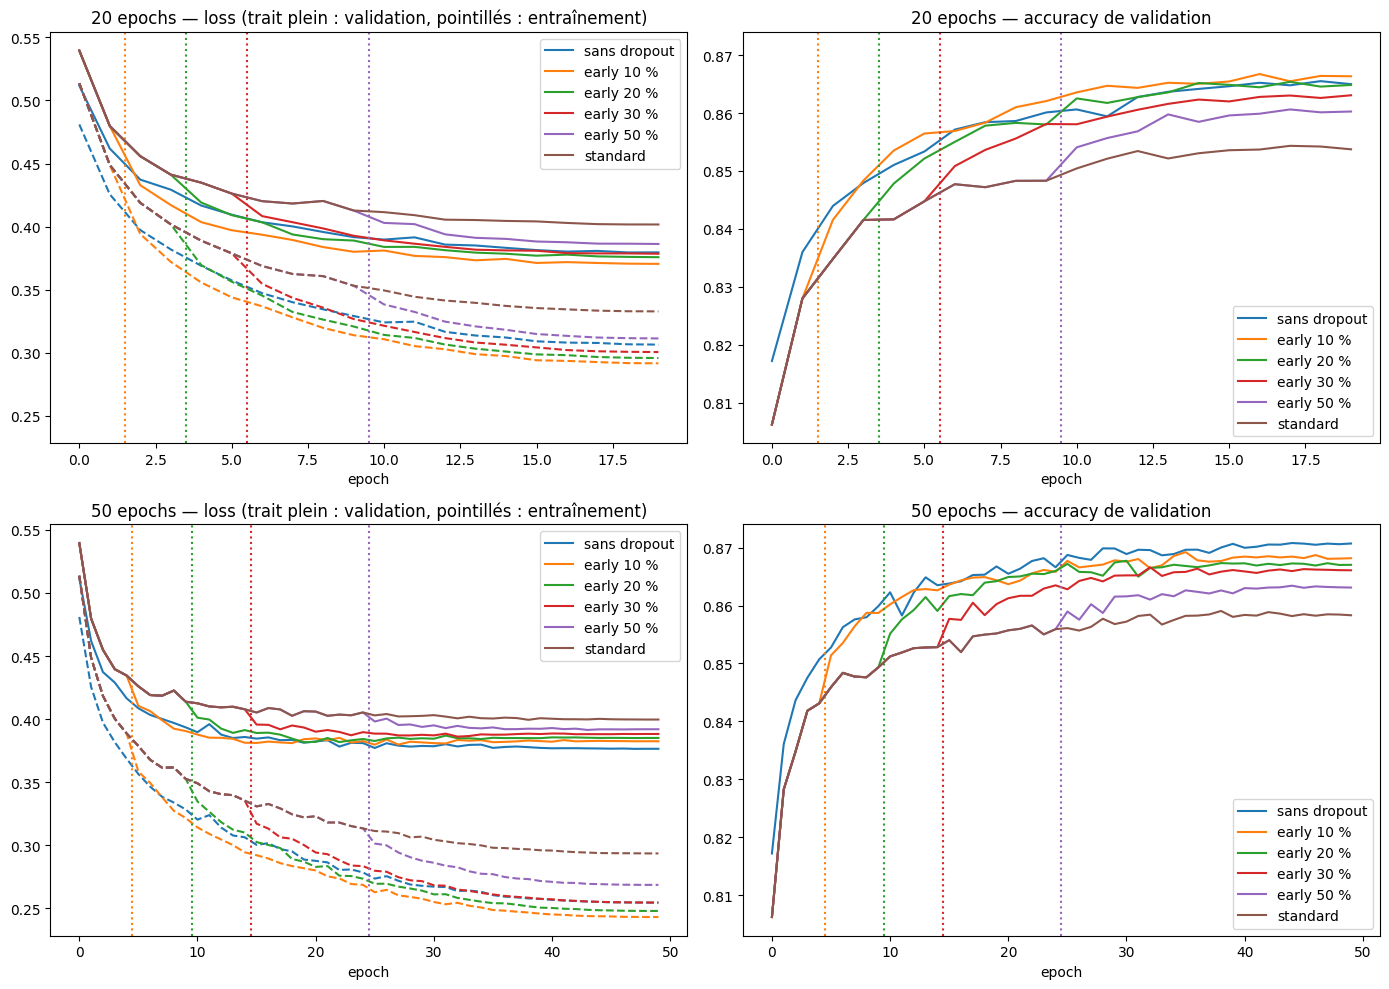

In [17]:
# courbes moyennes sur les graines 
# gauche : loss (validation en trait plein, entraînement en pointillés) ; droite : accuracy de validation
couleurs = plt.rcParams["axes.prop_cycle"].by_key()["color"]

def nom(frac):
    if frac == 0:
        return "sans dropout"
    if frac == 1:
        return "standard"
    return f"early {round(frac * 100)} %"

fig, axes = plt.subplots(len(EPOCHS_LIST), 2, figsize=(14, 5 * len(EPOCHS_LIST)), sharey="col")
for r, E in enumerate(EPOCHS_LIST):
    d = pd.concat(pd.read_csv(f) for f in glob.glob(f"{OUT}/{CADRE}_w{WIDTH}_e{E}_frac*_s*.csv"))
    d = d[d.seed.isin(SEEDS) & d.frac.isin(EARLY_GRID)]
    moy = d.groupby(["frac", "epoch"])[["train_loss", "val_loss", "val_acc"]].mean().reset_index()

    for k, frac in enumerate(sorted(moy.frac.unique())):
        c = couleurs[k % len(couleurs)]
        m = moy[moy.frac == frac]
        axes[r, 0].plot(m.epoch, m.val_loss, color=c, label=nom(frac))
        axes[r, 0].plot(m.epoch, m.train_loss, color=c, ls="--")
        axes[r, 1].plot(m.epoch, m.val_acc, color=c, label=nom(frac))
        if 0 < frac < 1:                       # fin de la phase de dropout
            for ax in axes[r]:
                ax.axvline(round(frac * E) - 0.5, color=c, ls=":", lw=1.5)

    axes[r, 0].set_title(f"{E} epochs — loss (trait plein : validation, pointillés : entraînement)")
    axes[r, 1].set_title(f"{E} epochs — accuracy de validation")
    for ax in axes[r]:
        ax.set_xlabel("epoch")
        ax.legend()

plt.tight_layout(); plt.show()